# Relatório 3: CNC
Interpolação e ajuste de função: Lagrange, Newton (diferenças divididas), Spline Cúbica Natural e Regressão Linear.

## Imports

In [27]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

## Biblioteca de métodos
As funções são as mesmas dos arquivos em `methods/`. Duas adaptações pro que o enunciado pede: `coeficientes_spline` converte as segundas derivadas da spline nos coeficientes `a_i, b_i, c_i, d_i` de cada intervalo, e `metricas` calcula `Sr`, `RMSE` e `R²` na escala original dos dados (a `regress` devolve `syx` e `R²`, mas não o `Sr`).

### Impressão de tabelas

In [28]:
# imprime uma tabela simples: colunas = lista de nomes, linhas = lista de listas
def imprimir_tabela(colunas, linhas):
    print(" | ".join(f"{c:>12}" for c in colunas))
    print("-" * (15 * len(colunas)))
    for linha in linhas:
        print(" | ".join(f"{'-':>12}" if v is None else f"{v:>12.6g}" for v in linha))

### Polinômio de Lagrange
`p_n(x) = Σ y_i L_i(x)`, com `L_i(x) = Π (x - x_j)/(x_i - x_j)`, `j != i`. Calcula o valor do polinômio num ponto `xi`, sem tabela nenhuma.

In [29]:
def lagrange(x, y, n, xi):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)

    soma = 0.0
    for i in range(n + 1):
        # começa com y_i e vai multiplicando pelos fatores de L_i(xi)
        produto = y[i]
        for j in range(n + 1):
            # o fator j = i é pulado (dava 0/0, e a definição do L_i já exclui ele)
            if i != j:
                produto = produto * (xi - x[j]) / (x[i] - x[j])
        soma = soma + produto

    return soma

### Interpolação de Newton em diferenças divididas
Constrói o polinômio termo a termo. Devolve `yint` (valor de cada grau em `xi`), `ea` (o que cada grau acrescentou) e a tabela `fdd`, cuja 1ª linha são os coeficientes do polinômio.

In [30]:
def newton_interpolacao(x, y, n, xi):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)

    # tabela das diferenças divididas. Só o triângulo superior esquerdo é usado (fdd[i, j] existe pra i + j <= n)
    fdd = np.zeros((n + 1, n + 1))

    # coluna 0 = os próprios valores de y (diferença dividida de ordem 0)
    for i in range(n + 1):
        fdd[i, 0] = y[i]

    # as outras colunas, j = ordem. Cada coluna usa a anterior, por isso o j é o laço de fora
    for j in range(1, n + 1):
        for i in range(n - j + 1):
            fdd[i, j] = (fdd[i + 1, j - 1] - fdd[i, j - 1]) / (x[i + j] - x[i])

    # monta o polinômio avaliando em xi, 1 termo por vez
    xterm = 1.0 # guarda o produto (xi - x0)(xi - x1)...(xi - x_{order-1}), reaproveita o do termo anterior
    yint = np.zeros(n + 1)
    ea = np.zeros(n)
    yint[0] = fdd[0, 0]

    for order in range(1, n + 1):
        xterm = xterm * (xi - x[order - 1])
        yint2 = yint[order - 1] + fdd[0, order] * xterm
        ea[order - 1] = yint2 - yint[order - 1] # erro estimado = o que esse termo acrescentou
        yint[order] = yint2

    return yint, ea, fdd

### Spline cúbica natural
Uma cúbica por intervalo, com a curva, a 1ª e a 2ª derivada contínuas nos nós e `d2x_0 = d2x_n = 0` (natural). As incógnitas são as segundas derivadas nos nós, que saem de um sistema **tridiagonal** (`tridiag`, `decomp` e `subst`). `interpol` avalia a cúbica do intervalo e `spline` junta tudo.

In [31]:
# monta o sistema tridiagonal. A primeira e a última linha são diferentes pq d2x_0 = d2x_n = 0 (natural)
def tridiag(x, y, n):
    e = np.zeros(n + 1)
    f = np.zeros(n + 1)
    g = np.zeros(n + 1)
    r = np.zeros(n + 1)

    # primeira linha (nó 1): n tem e, pq ele multiplicaria o d2x_0 que é 0
    f[1] = 2 * (x[2] - x[0])
    g[1] = x[2] - x[1]
    r[1] = 6 / (x[2] - x[1]) * (y[2] - y[1])
    r[1] = r[1] + 6 / (x[1] - x[0]) * (y[0] - y[1])

    # linhas do meio (nós 2 até n-2)
    for i in range(2, n - 1):
        e[i] = x[i] - x[i - 1]
        f[i] = 2 * (x[i + 1] - x[i - 1])
        g[i] = x[i + 1] - x[i]
        r[i] = 6 / (x[i + 1] - x[i]) * (y[i + 1] - y[i])
        r[i] = r[i] + 6 / (x[i] - x[i - 1]) * (y[i - 1] - y[i])

    # última linha (nó n-1): n tem g, pq ele multiplicaria o d2x_n que é 0
    # com n = 2 só existe 1 incógnita, a primeira linha já é o sistema inteiro (se rodasse isso o r[1] seria somado 2x)
    if n > 2:
        e[n - 1] = x[n - 1] - x[n - 2]
        f[n - 1] = 2 * (x[n] - x[n - 2])
        r[n - 1] = 6 / (x[n] - x[n - 1]) * (y[n] - y[n - 1])
        r[n - 1] = r[n - 1] + 6 / (x[n - 1] - x[n - 2]) * (y[n - 2] - y[n - 1])

    return e, f, g, r

# decomposição LU do sistema tridiagonal (sem pivotação). Escreve em cima de e e f
# o e vira o multiplicador (L) e o f vira a diagonal da U. O g n muda
def decomp(e, f, g, n):
    for k in range(2, n + 1):
        e[k] = e[k] / f[k - 1]
        f[k] = f[k] - e[k] * g[k - 1]

# resolve o sistema já decomposto. Escreve a solução em x e estraga o r
def subst(e, f, g, r, n, x):
    # substituição progressiva (aplica o L no r)
    for k in range(2, n + 1):
        r[k] = r[k] - e[k] * r[k - 1]

    # substituição retroativa (resolve a U)
    x[n] = r[n] / f[n]
    for k in range(n - 1, 0, -1):
        x[k] = (r[k] - g[k] * x[k + 1]) / f[k]

# acha o intervalo [x_(i-1), x_i] que tem o xu e avalia a cúbica dele (e as derivadas)
def interpol(x, y, n, d2x, xu):
    flag = 0
    i = 1
    yu = dy = d2y = np.nan

    while True:
        if xu >= x[i - 1] and xu <= x[i]:
            # coeficientes da cúbica desse intervalo
            c1 = d2x[i - 1] / 6 / (x[i] - x[i - 1])
            c2 = d2x[i] / 6 / (x[i] - x[i - 1])
            c3 = y[i - 1] / (x[i] - x[i - 1]) - d2x[i - 1] * (x[i] - x[i - 1]) / 6
            c4 = y[i] / (x[i] - x[i - 1]) - d2x[i] * (x[i] - x[i - 1]) / 6

            # valor da spline
            t1 = c1 * (x[i] - xu) ** 3
            t2 = c2 * (xu - x[i - 1]) ** 3
            t3 = c3 * (x[i] - xu)
            t4 = c4 * (xu - x[i - 1])
            yu = t1 + t2 + t3 + t4

            # 1a derivada
            t1 = -3 * c1 * (x[i] - xu) ** 2
            t2 = 3 * c2 * (xu - x[i - 1]) ** 2
            t3 = -c3
            t4 = c4
            dy = t1 + t2 + t3 + t4

            # 2a derivada (é uma reta, vai de d2x_(i-1) até d2x_i)
            t1 = 6 * c1 * (x[i] - xu)
            t2 = 6 * c2 * (xu - x[i - 1])
            d2y = t1 + t2

            flag = 1
        else:
            i = i + 1

        if i == n + 1 or flag == 1:
            break

    if flag == 0:
        print("fora do intervalo")
        return yu, dy, d2y, 1

    return yu, dy, d2y, 0

def spline(x, y, xu):
    # copia pra n estragar os vetores originais
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n = len(x) - 1 # n intervalos = n+1 pontos

    if n < 2:
        raise ValueError("a spline cúbica precisa de pelo menos 3 pontos")

    d2x = np.zeros(n + 1) # d2x[0] = d2x[n] = 0 (condição natural), os de dentro o subst preenche

    e, f, g, r = tridiag(x, y, n)
    decomp(e, f, g, n - 1)        # o sistema só tem n-1 incógnitas (nós internos)
    subst(e, f, g, r, n - 1, d2x)
    yu, dy, d2y, info = interpol(x, y, n, d2x, xu)

    return yu, dy, d2y, d2x, info

`coeficientes_spline`: converte as `d2x` pra forma `a + b(x - x_i) + c(x - x_i)² + d(x - x_i)³` do enunciado.

In [32]:
# converte as d2x (segundas derivadas nos nós) pros coeficientes de cada intervalo, na forma que o enunciado pede:
#   S_i(x) = a_i + b_i (x - x_i) + c_i (x - x_i)² + d_i (x - x_i)³,   x_i <= x <= x_(i+1)
# derivando a cúbica do chapra em x_i, com h = x_(i+1) - x_i:
#   a_i = y_i | b_i = (y_(i+1) - y_i)/h - h (2 d2x_i + d2x_(i+1))/6 | c_i = d2x_i/2 | d_i = (d2x_(i+1) - d2x_i)/(6h)
# retorna uma matriz n x 4, onde a linha i = [a_i, b_i, c_i, d_i] do intervalo [x_i, x_(i+1)]
def coeficientes_spline(x, y, d2x):
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n = len(x) - 1

    coef = np.zeros((n, 4))
    for i in range(n):
        h = x[i + 1] - x[i]
        coef[i, 0] = y[i]
        coef[i, 1] = (y[i + 1] - y[i]) / h - h * (2 * d2x[i] + d2x[i + 1]) / 6
        coef[i, 2] = d2x[i] / 2
        coef[i, 3] = (d2x[i + 1] - d2x[i]) / (6 * h)

    return coef

### Regressão linear por mínimos quadrados
Ajusta `y = a0 + a1 x` minimizando `Sr`. Devolve `a1, a0, syx, r2, info`.

In [33]:
def regress(x, y):
    # copia pra n estragar os vetores originais
    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)
    n = len(x)

    sumx = 0.0
    sumy = 0.0
    sumxy = 0.0
    sumx2 = 0.0
    st = 0.0
    sr = 0.0

    # somatórios que aparecem nas equações normais
    for i in range(n):
        sumx = sumx + x[i]
        sumy = sumy + y[i]
        sumxy = sumxy + x[i] * y[i]
        sumx2 = sumx2 + x[i] * x[i]

    xm = sumx / n
    ym = sumy / n

    # se todos os x forem iguais, a reta é vertical e n dá pra escrever como y = a0 + a1 x
    den = n * sumx2 - sumx * sumx

    # compara os x direto, pq o den em float n dá 0 exato (ex: x = 0.7 sai ~1e-16)
    if np.all(x == x[0]):
        print("todos os x são iguais, n existe reta de regressão")
        return np.nan, np.nan, np.nan, np.nan, 1

    a1 = (n * sumxy - sumx * sumy) / den
    a0 = ym - a1 * xm

    # st = erro em volta da média, sr = erro em volta da reta
    for i in range(n):
        st = st + (y[i] - ym) ** 2
        sr = sr + (y[i] - a1 * x[i] - a0) ** 2

    # n - 2 pq a gente perdeu 2 graus de liberdade estimando a0 e a1
    if n > 2:
        syx = (sr / (n - 2)) ** 0.5
    else:
        syx = np.nan

    # st = 0 quando todos os y são iguais (reta horizontal), aí o r2 n faz sentido
    if st != 0:
        r2 = (st - sr) / st
    else:
        r2 = np.nan

    return a1, a0, syx, r2, 0

`metricas`: `Sr`, `RMSE` e `R²` de um modelo qualquer, na escala original de `y`.

In [34]:
# Sr, RMSE e R² sempre na escala original dos dados, assim dá pra comparar modelos diferentes com a mesma régua
#   Sr   = soma de (y_i - modelo_i)²
#   RMSE = raiz(Sr / n)
#   R²   = 1 - Sr / St, com St = soma de (y_i - média de y)²
def metricas(y, y_modelo):
    y = np.array(y, dtype=float)
    y_modelo = np.array(y_modelo, dtype=float)
    sr = np.sum((y - y_modelo) ** 2)
    st = np.sum((y - np.mean(y)) ** 2)
    return sr, np.sqrt(sr / len(y)), 1 - sr / st

## Exercício 1: Sensor resistivo (Lagrange)
5 medidas de resistência `R(T)`, logo grau `n = 4`. Letras: (a) polinômio `P4(T)` pela fórmula de Lagrange, (b) estimativas em `T = 35 °C` e `T = 65 °C`, (c) gráfico da curva em `0 <= T <= 80 °C` com os dois pontos estimados.

### Dados

In [35]:
T = [0, 20, 40, 60, 80]                        # °C
R = [100.00, 107.79, 115.54, 123.24, 130.90]   # Ω
n = len(T) - 1                                 # grau do polinômio (5 pontos -> grau 4)

### a) polinômio interpolador

In [36]:
# a função lagrange só avalia o polinômio num ponto, então pra ter a EXPRESSÃO de P4(T) monto a mesma soma com o sympy
# (em frações exatas, pra n perder nada no arredondamento)
# P_n(T) = soma de R_i * L_i(T), com L_i(T) = produto de (T - T_j)/(T_i - T_j), j != i
sT = sp.symbols('T')
P = 0
print("a) funções base de Lagrange")
for i in range(n + 1):
    Li = 1
    for j in range(n + 1):
        if i != j:
            Li = Li * (sT - T[j]) / sp.Integer(T[i] - T[j])
    print(f"  L_{i}(T) =", sp.factor(Li))
    P = P + sp.Rational(str(R[i])) * Li

P = sp.expand(P)
print("\nP4(T) =", P)
coef_P = [float(c) for c in sp.Poly(P, sT).all_coeffs()]
print("coeficientes (T^4 ... T^0) =", coef_P)

# confere com a lib (np.polyfit com grau n passando por todos os pontos dá o mesmo polinômio, pq ele é único)
print("\n|coef sympy - np.polyfit| =", np.max(np.abs(np.array(coef_P) - np.polyfit(T, R, n))))

# o polinômio tem que passar exatamente nos 5 pontos medidos
err_ex1 = max(abs(lagrange(T, R, n, Tk) - Rk) for Tk, Rk in zip(T, R))
print("passa nos pontos? max|P(T_i) - R_i| =", err_ex1)

a) funções base de Lagrange
  L_0(T) = (T - 80)*(T - 60)*(T - 40)*(T - 20)/3840000
  L_1(T) = -T*(T - 80)*(T - 60)*(T - 40)/960000
  L_2(T) = T*(T - 80)*(T - 60)*(T - 20)/640000
  L_3(T) = -T*(T - 80)*(T - 40)*(T - 20)/960000
  L_4(T) = T*(T - 60)*(T - 40)*(T - 20)/3840000

P4(T) = T**4/192000000 - T**3/1200000 - 7*T**2/480000 + 4681*T/12000 + 100
coeficientes (T^4 ... T^0) = [5.208333333333334e-09, -8.333333333333333e-07, -1.4583333333333333e-05, 0.39008333333333334, 100.0]

|coef sympy - np.polyfit| = 9.325873406851315e-15
passa nos pontos? max|P(T_i) - R_i| = 1.4210854715202004e-14


**Resposta da letra a:** cada `L_i(T)` vale 1 em `T_i` e 0 nos outros 4 pontos (as 5 funções base acima), e `P4(T) = Σ R_i L_i(T)` dá

`P4(T) = 100 + 0,390083 T - 1,4583e-5 T² - 8,3333e-7 T³ + 5,2083e-9 T⁴`

ou, em fração exata, `T⁴/192000000 - T³/1200000 - 7T²/480000 + 4681T/12000 + 100`. Bate com o `np.polyfit` (o polinômio de grau 4 que passa por 5 pontos é único) e passa nos 5 pontos com erro na ordem do arredondamento (~1e-14). Os termos de grau 3 e 4 são minúsculos: a curva é quase uma parábola, com uma leve concavidade pra baixo (o coeficiente de `T²` é negativo).

### b) estimativas em T = 35 °C e T = 65 °C

In [37]:
print("b) estimativas")
T_est = [35, 65]
R_est = []
for Ti in T_est:
    Ri = lagrange(T, R, n, Ti)
    R_est.append(Ri)
    # conferência: o mesmo valor pelo polinômio do sympy, e uma interpolação linear só entre os 2 vizinhos (np.interp) pra ter noção de ordem de grandeza
    print(f"  R({Ti}) = {Ri:.4f} Ω | sympy = {float(P.subs(sT, Ti)):.4f} | linear entre vizinhos = {np.interp(Ti, T, R):.4f}")

b) estimativas
  R(35) = 113.6071 Ω | sympy = 113.6071 | linear entre vizinhos = 113.6025
  R(65) = 125.1579 Ω | sympy = 125.1579 | linear entre vizinhos = 125.1550


**Resposta da letra b:** `R(35) ≈ 113,607 Ω` e `R(65) ≈ 125,158 Ω`. O polinômio do sympy dá o mesmo valor, e a interpolação linear entre os dois vizinhos fica a menos de 0,01 Ω de distância (113,603 e 125,155): faz sentido, pq os dados quase não têm curvatura, então o `P4` só corrige a reta nos centésimos.

### c) gráfico

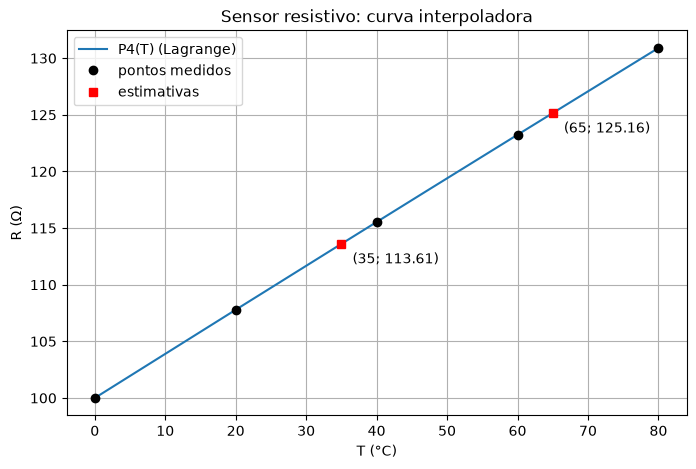

In [38]:
Ts = np.linspace(0, 80, 200)
Rs = [lagrange(T, R, n, t) for t in Ts] # a lagrange avalia 1 ponto por vez

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(Ts, Rs, label="P4(T) (Lagrange)")
ax.plot(T, R, "o", color="black", label="pontos medidos")
ax.plot(T_est, R_est, "s", color="red", label="estimativas")
for t, r in zip(T_est, R_est):
    ax.annotate(f"({t}; {r:.2f})", (t, r), textcoords="offset points", xytext=(8, -14))
ax.set_xlabel("T (°C)")
ax.set_ylabel("R (Ω)")
ax.set_title("Sensor resistivo: curva interpoladora")
ax.legend()
ax.grid(True)
plt.show()

**Resposta da letra c:** a curva passa exatamente pelos 5 pontos pretos e os dois pontos estimados (vermelho) caem em cima dela, entre os pontos medidos. A resistência cresce de forma quase linear com a temperatura (~0,39 Ω/°C), com uma pequena concavidade. Como os pontos são igualmente espaçados e os dados são suaves, o grau 4 n oscila entre os nós.

## Exercício 2: Bomba centrífuga (Newton, diferenças divididas)
5 medidas de eficiência `η(Q)`, grau `n = 4`. Letras: (a) diferenças divididas de Newton, (b) estimativas em `Q = 32` e `Q = 45 m³/h`, (c) gráfico em `10 <= Q <= 52 m³/h`, (d) novo ponto `(60 ; 72)` na tabela e o termo necessário pra `P5(Q)`.

### Dados

In [39]:
Q = [10, 18, 27, 39, 52]    # m³/h
eta = [58, 68, 76, 80, 77]  # %
n = len(Q) - 1              # grau do polinômio (5 pontos -> grau 4)

### a) diferenças divididas de Newton

In [40]:
# a tabela só existe no triângulo i + j <= n, o resto da matriz fdd é zero de enchimento (vira "-" na impressão)
_, _, fdd = newton_interpolacao(Q, eta, n, Q[0])
linhas = [[Q[i], *[fdd[i, j] if i + j <= n else None for j in range(n + 1)]] for i in range(n + 1)]
print("a) tabela de diferenças divididas")
imprimir_tabela(["Q", "f[xi]", "ordem 1", "ordem 2", "ordem 3", "ordem 4"], linhas)
print("\ncoeficientes do polinômio (1a linha) =", fdd[0])

# confere o polinômio completo com a lib (np.polyfit com grau n passando por todos os pontos dá o mesmo polinômio, pq ele é único)
Qc = np.linspace(10, 52, 50)
dif = max(abs(newton_interpolacao(Q, eta, n, q)[0][n] - np.polyval(np.polyfit(Q, eta, n), q)) for q in Qc)
print("max|Newton - np.polyfit| em 50 pontos =", dif)

err_ex2 = max(abs(newton_interpolacao(Q, eta, n, Qk)[0][n] - ek) for Qk, ek in zip(Q, eta))
print("passa nos pontos? max|P(Q_i) - η_i| =", err_ex2)

a) tabela de diferenças divididas
           Q |        f[xi] |      ordem 1 |      ordem 2 |      ordem 3 |      ordem 4
------------------------------------------------------------------------------------------
          10 |           58 |         1.25 |   -0.0212418 | -0.000179765 |  7.00487e-06
          18 |           68 |     0.888889 |    -0.026455 |  0.000114439 |            -
          27 |           76 |     0.333333 |   -0.0225641 |            - |            -
          39 |           80 |    -0.230769 |            - |            - |            -
          52 |           77 |            - |            - |            - |            -

coeficientes do polinômio (1a linha) = [ 5.80000000e+01  1.25000000e+00 -2.12418301e-02 -1.79765393e-04
  7.00486502e-06]
max|Newton - np.polyfit| em 50 pontos = 1.1368683772161603e-13
passa nos pontos? max|P(Q_i) - η_i| = 1.4210854715202004e-14


**Resposta da letra a:** a 1ª linha da tabela são os coeficientes, então

`P4(Q) = 58 + 1,25 (Q-10) - 0,0212418 (Q-10)(Q-18) - 1,79765e-4 (Q-10)(Q-18)(Q-27) + 7,00487e-6 (Q-10)(Q-18)(Q-27)(Q-39)`

Os coeficientes caem rápido de ordem pra ordem (1,25 -> 0,02 -> 1,8e-4 -> 7e-6), sinal de que os termos de grau mais alto são correções pequenas em cima dos anteriores. O polinômio é o mesmo do `np.polyfit` e passa nos 5 pontos.

### b) estimativas em Q = 32 e Q = 45

In [41]:
# o enunciado escreve "estimar a vazão quando a eficiência for η(32) e η(45)", mas nos dados Q é a entrada e η é a saída.
# Então o que dá pra estimar é a EFICIÊNCIA nas vazões Q = 32 e Q = 45 m³/h (e é isso que o gráfico da letra c pede pra marcar)
Q_est = [32, 45]
eta_est = []
print("b) estimativas")
for Qi in Q_est:
    yint, ea, _ = newton_interpolacao(Q, eta, n, Qi)
    eta_est.append(yint[n])
    print(f"\nQ = {Qi} m³/h")
    imprimir_tabela(["grau", "η(Q) (%)", "ea"], [[k, yint[k], None if k == 0 else ea[k - 1]] for k in range(n + 1)])

b) estimativas

Q = 32 m³/h
        grau |     η(Q) (%) |           ea
---------------------------------------------
           0 |           58 |            -
           1 |         85.5 |         27.5
           2 |      78.9575 |     -6.54248
           3 |      78.6807 |    -0.276839
           4 |      78.6052 |   -0.0755124

Q = 45 m³/h
        grau |     η(Q) (%) |           ea
---------------------------------------------
           0 |           58 |            -
           1 |       101.75 |        43.75
           2 |      81.6765 |     -20.0735
           3 |      78.6187 |     -3.05781
           4 |      79.3336 |     0.714917


**Resposta da letra b:** `η(32) ≈ 78,61 %` e `η(45) ≈ 79,33 %` (grau 4). Nota: o enunciado pede "a vazão quando a eficiência for η(32)", mas pelos dados o que se estima é a eficiência nas vazões 32 e 45 m³/h, foi o que fiz.

- Em `Q = 32` a estimativa estabiliza: o termo do grau 4 acrescenta só -0,076 (os graus 3 e 4 dão 78,68 e 78,61).
- Em `Q = 45` a correção do último termo ainda é +0,71, ou seja, a estimativa é menos firme. É esperado: 45 fica entre 39 e 52, perto da ponta da tabela, e a curva muda de direção por ali (a eficiência sobe até 80 % e cai pra 77 %).

### c) gráfico

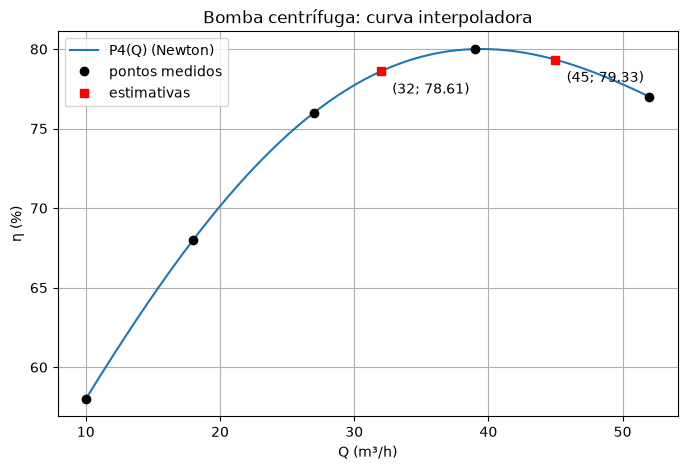

máximo de P4 em 10 <= Q <= 52: η = 80.00 % em Q = 39.5 m³/h


In [42]:
Qs = np.linspace(10, 52, 200)
etas = [newton_interpolacao(Q, eta, n, q)[0][n] for q in Qs]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(Qs, etas, label="P4(Q) (Newton)")
ax.plot(Q, eta, "o", color="black", label="pontos medidos")
ax.plot(Q_est, eta_est, "s", color="red", label="estimativas")
for q, e in zip(Q_est, eta_est):
    ax.annotate(f"({q}; {e:.2f})", (q, e), textcoords="offset points", xytext=(8, -16))
ax.set_xlabel("Q (m³/h)")
ax.set_ylabel("η (%)")
ax.set_title("Bomba centrífuga: curva interpoladora")
ax.legend()
ax.grid(True)
plt.show()

# máximo da curva interpolada (aproxima o ponto de melhor eficiência da bomba)
i_max = np.argmax(etas)
print(f"máximo de P4 em 10 <= Q <= 52: η = {etas[i_max]:.2f} % em Q = {Qs[i_max]:.1f} m³/h")

**Resposta da letra c:** a curva passa pelos 5 pontos pretos e os dois pontos estimados (vermelho) ficam sobre ela. A eficiência sobe rápido com a vazão no começo e depois achata, com um máximo de ~80,0 % em `Q ≈ 39,5 m³/h`, praticamente em cima do ponto medido de 39 m³/h (80 %). Depois disso a eficiência cai (77 % em 52 m³/h). É um comportamento típico de curva de bomba: tem uma vazão de melhor eficiência, e longe dela a eficiência cai. Esse máximo vem do polinômio, n foi medido, então vale só como estimativa.

### d) novo ponto Q = 60 m³/h e η = 72 %

d) tabela com o ponto novo
           Q |        f[xi] |      ordem 1 |      ordem 2 |      ordem 3 |      ordem 4 |      ordem 5
---------------------------------------------------------------------------------------------------------
          10 |           58 |         1.25 |   -0.0212418 | -0.000179765 |  7.00487e-06 | -1.39885e-07
          18 |           68 |     0.888889 |    -0.026455 |  0.000114439 |  1.06233e-08 |            -
          27 |           76 |     0.333333 |   -0.0225641 |  0.000114885 |            - |            -
          39 |           80 |    -0.230769 |   -0.0187729 |            - |            - |            -
          52 |           77 |       -0.625 |            - |            - |            - |            -
          60 |           72 |            - |            - |            - |            - |            -

coeficientes a0...a4 iguais aos de antes? True
a5 = f[x0,...,x5] = -1.3988483514224854e-07
diagonal nova = [72.0, -0.625, -0.018772893772893772, 

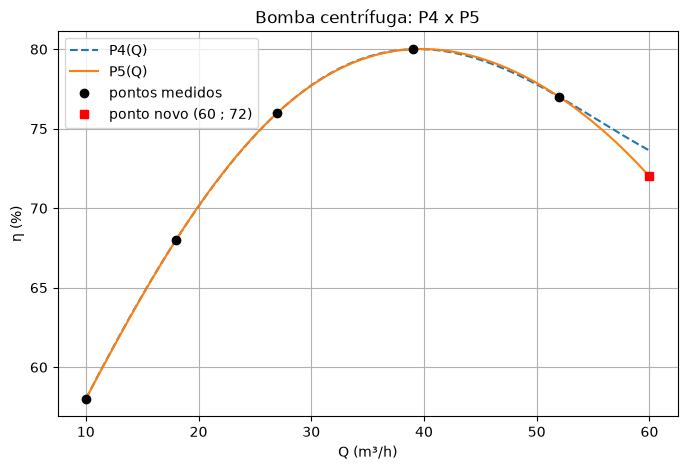

In [43]:
# o ponto novo vai no FIM das listas. O Newton n exige x ordenado, e assim as linhas antigas da tabela ficam como estavam
Q_novo = Q + [60]
eta_novo = eta + [72]
n_novo = len(Q_novo) - 1

_, _, fdd_novo = newton_interpolacao(Q_novo, eta_novo, n_novo, Q_novo[0])
linhas = [[Q_novo[i], *[fdd_novo[i, j] if i + j <= n_novo else None for j in range(n_novo + 1)]] for i in range(n_novo + 1)]
print("d) tabela com o ponto novo")
imprimir_tabela(["Q", "f[xi]", "ordem 1", "ordem 2", "ordem 3", "ordem 4", "ordem 5"], linhas)

# os coeficientes a0...a4 (1a linha) n mudaram. O único termo novo é a5 = f[x0,...,x5]
print("\ncoeficientes a0...a4 iguais aos de antes?", np.allclose(fdd_novo[0, :n + 1], fdd[0]))
a5 = fdd_novo[0, n_novo]
print("a5 = f[x0,...,x5] =", a5)

# a diagonal nova (1 entrada por coluna) é a única parte da tabela que foi calculada de novo
print("diagonal nova =", [float(fdd_novo[n_novo - j, j]) for j in range(n_novo + 1)])

# conferência: a5 é o que falta pro P5 passar no ponto novo.  a5 = (72 - P4(60)) / produto de (60 - x_i)
p4_60 = newton_interpolacao(Q, eta, n, 60)[0][n]
prod = np.prod([60 - q for q in Q])
print(f"P4(60) = {p4_60:.4f} (extrapolação, o ponto real é 72) | (72 - P4(60)) / prod = {(72 - p4_60) / prod}")

# efeito nas estimativas: P5 - P4 é só o termo novo, a5 (Q - x0)...(Q - x4)
print("\nefeito nas estimativas")
for Qi in Q_est:
    y4 = newton_interpolacao(Q, eta, n, Qi)[0][n]
    y5 = newton_interpolacao(Q_novo, eta_novo, n_novo, Qi)[0][n_novo]
    print(f"  Q = {Qi}: P4 = {y4:.4f} | P5 = {y5:.4f} | diferença = {y5 - y4:.4f} | a5 * prod = {a5 * np.prod([Qi - q for q in Q]):.4f}")

# gráfico extra: P4 e P5 com o ponto novo
Qs2 = np.linspace(10, 60, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(Qs2, [newton_interpolacao(Q, eta, n, q)[0][n] for q in Qs2], "--", label="P4(Q)")
ax.plot(Qs2, [newton_interpolacao(Q_novo, eta_novo, n_novo, q)[0][n_novo] for q in Qs2], label="P5(Q)")
ax.plot(Q, eta, "o", color="black", label="pontos medidos")
ax.plot([60], [72], "s", color="red", label="ponto novo (60 ; 72)")
ax.set_xlabel("Q (m³/h)")
ax.set_ylabel("η (%)")
ax.set_title("Bomba centrífuga: P4 x P5")
ax.legend()
ax.grid(True)
plt.show()

**Resposta da letra d:** o termo novo é `a5 = f[x0,...,x5] ≈ -1,3988e-7`, e `P5(Q) = P4(Q) + a5 (Q-10)(Q-18)(Q-27)(Q-39)(Q-52)`.

- Só a diagonal nova da tabela foi calculada (a última linha, com os valores `72`, `-0,625`, `-0,01877`, `1,149e-4`, `1,06e-8` e `-1,3988e-7`). Todo o resto, inclusive os coeficientes `a0...a4`, ficou igual.
- O `a5` é exatamente o que falta pro polinômio passar no ponto novo: `P4` extrapolaria `P4(60) ≈ 73,63` e o ponto real é 72, então o termo novo tem que cobrir essa diferença de `-1,63`. A conta `a5 = (72 - P4(60)) / Π(60 - x_i)` reproduz o valor da tabela (conferência acima).
- O efeito nas estimativas é pequeno: `η(32)` vai de 78,605 pra 78,575 e `η(45)` de 79,334 pra 79,434. Dá pra ver no gráfico que `P4` e `P5` quase se sobrepõem dentro de `[10, 52]` e só se separam perto do ponto novo.

**Por que a forma de Newton é conveniente quando chegam dados novos:** cada termo do polinômio só depende dos pontos anteriores, então um ponto novo vira **uma linha a mais na tabela e um termo a mais no polinômio**, sem mexer em nada do que já foi calculado (custo ~n operações). No Lagrange todas as funções base `L_i` mudam quando entra um ponto (refaz tudo), e na forma monomial `a0 + a1 x + ...` seria preciso resolver o sistema de Vandermonde de novo. De quebra, o próprio termo novo serve de estimativa do erro (`ea`): se ele é pequeno, o grau anterior já tava bom.

## Exercício 3: Perfil topográfico (Spline Cúbica Natural)
6 elevações medidas, logo `n = 5` intervalos, 1 cúbica por intervalo com `S''(x_0) = S''(x_5) = 0`. Letras: (a) coeficientes `a_i, b_i, c_i, d_i`, (b) elevações em `x = 125`, `230` e `500 m`, (c) gráfico do perfil completo.

### Dados

In [44]:
x = [0, 80, 170, 290, 420, 600]            # m (distância)
z = [12.0, 14.8, 13.9, 18.1, 17.4, 20.2]   # m (elevação)
n = len(x) - 1                             # número de intervalos (6 pontos -> 5 intervalos)

### a) coeficientes de cada intervalo

In [45]:
# o spline() devolve as segundas derivadas nos nós (d2x). A partir delas saem os coeficientes de cada intervalo
_, _, _, d2x, _ = spline(x, z, x[0])
coef = coeficientes_spline(x, z, d2x)

print("a) segundas derivadas nos nós (d2x) =", d2x)
print("\nS_i(x) = a_i + b_i (x - x_i) + c_i (x - x_i)² + d_i (x - x_i)³ em [x_i, x_(i+1)]")
imprimir_tabela(["i", "x_i", "x_(i+1)", "a_i", "b_i", "c_i", "d_i"], [[i, x[i], x[i + 1], *coef[i]] for i in range(n)])

# conferências
# 1) a forma a + b dx + c dx² + d dx³ tem que dar o mesmo valor que o spline() (forma do chapra) em qualquer ponto
def avaliar(coef, x, xu):
    i = min(np.searchsorted(x, xu, side="right") - 1, len(coef) - 1)
    dx = xu - x[i]
    return coef[i, 0] + coef[i, 1] * dx + coef[i, 2] * dx**2 + coef[i, 3] * dx**3

xg = np.linspace(0, 600, 200)
print("\n|forma a,b,c,d - spline()| máx em 200 pontos =", max(abs(avaliar(coef, x, xu) - spline(x, z, xu)[0]) for xu in xg))

# 2) continuidade da curva, da 1a e da 2a derivada nos nós internos (S_i(x_(i+1)) = S_(i+1)(x_(i+1)) etc)
c0, c1, c2 = 0.0, 0.0, 0.0
for i in range(n - 1):
    h = x[i + 1] - x[i]
    a_i, b_i, c_i, d_i = coef[i]
    c0 = max(c0, abs(a_i + b_i * h + c_i * h**2 + d_i * h**3 - coef[i + 1, 0]))
    c1 = max(c1, abs(b_i + 2 * c_i * h + 3 * d_i * h**2 - coef[i + 1, 1]))
    c2 = max(c2, abs(2 * c_i + 6 * d_i * h - 2 * coef[i + 1, 2]))
print("descontinuidade máx nos nós internos: S =", c0, "| S' =", c1, "| S'' =", c2)

# 3) condição natural: S'' = 0 nas pontas
h_fim = x[n] - x[n - 1]
print("S''(x_0) =", 2 * coef[0, 2], "| S''(x_n) =", 2 * coef[n - 1, 2] + 6 * coef[n - 1, 3] * h_fim)

# 4) passa nos pontos medidos
err_ex3 = max(abs(spline(x, z, xk)[0] - zk) for xk, zk in zip(x, z))
print("passa nos pontos? max|S(x_i) - z_i| =", err_ex3)

# 5) confere com a lib (bc_type='natural' é a mesma condição d2x_0 = d2x_n = 0)
try:
    from scipy.interpolate import CubicSpline
    cs = CubicSpline(x, z, bc_type='natural')
    print("max|S - scipy| em 200 pontos =", np.max(np.abs(np.array([spline(x, z, xu)[0] for xu in xg]) - cs(xg))))
except ImportError:
    print("scipy n instalado, pulei a conferência")

a) segundas derivadas nos nós (d2x) = [ 0.         -0.00109063  0.00112017 -0.00085263  0.00038142  0.        ]

S_i(x) = a_i + b_i (x - x_i) + c_i (x - x_i)² + d_i (x - x_i)³ em [x_i, x_(i+1)]
           i |          x_i |      x_(i+1) |          a_i |          b_i |          c_i |          d_i
---------------------------------------------------------------------------------------------------------
           0 |            0 |           80 |           12 |    0.0495418 |            0 | -2.27215e-06
           1 |           80 |          170 |         14.8 |   0.00591643 | -0.000545317 |  4.09408e-06
           2 |          170 |          290 |         13.9 |   0.00724565 |  0.000560086 |    -2.74e-06
           3 |          290 |          420 |         18.1 |    0.0232984 | -0.000426313 |  1.58212e-06
           4 |          420 |          600 |         17.4 |  -0.00732985 |  0.000190712 |  -3.5317e-07

|forma a,b,c,d - spline()| máx em 200 pontos = 7.105427357601002e-15
descontinuid

**Resposta da letra a:** os coeficientes de cada intervalo estão na tabela acima, na forma `S_i(x) = a_i + b_i (x - x_i) + c_i (x - x_i)² + d_i (x - x_i)³` em `[x_i, x_(i+1)]`. O `a_i` é só a elevação do nó da esquerda, e `c_0 = 0` (a condição natural).

As conferências batem: a forma `a,b,c,d` dá o mesmo valor que o `spline()` (~1e-14), a curva, a 1ª e a 2ª derivada são contínuas nos nós internos (descontinuidade ~1e-15), `S'' = 0` nas duas pontas e o resultado coincide com o `CubicSpline` do scipy. As segundas derivadas nos nós ficam na ordem de 1e-3 ou menos, pq o perfil é suave.

### b) elevações em x = 125, 230 e 500 m

In [46]:
x_est = [125, 230, 500]
z_est = []
print("b) elevações estimadas")
for xu in x_est:
    yu, dy, d2y, _, info = spline(x, z, xu)
    z_est.append(yu)
    # só pra comparar: interpolação linear entre os 2 vizinhos e o polinômio de grau 5 por todos os pontos (lagrange)
    print(f"  z({xu}) = {yu:.4f} m | S'({xu}) = {dy:.5f} ({100 * dy:.2f} % de inclinação) | S'' = {d2y:.2e} | info = {info}")
    print(f"      linear entre vizinhos = {np.interp(xu, x, z):.4f} | polinômio de grau 5 = {lagrange(x, z, n, xu):.4f}")

b) elevações estimadas
  z(125) = 14.3350 m | S'(125) = -0.01829 (-1.83 % de inclinação) | S'' = 1.48e-05 | info = 0
      linear entre vizinhos = 14.3500 | polinômio de grau 5 = 13.9943
  z(230) = 15.7592 m | S'(230) = 0.04486 (4.49 % de inclinação) | S'' = 1.34e-04 | info = 0
      linear entre vizinhos = 16.0000 | polinômio de grau 5 = 15.5340
  z(500) = 17.8533 m | S'(500) = 0.01640 (1.64 % de inclinação) | S'' = 2.12e-04 | info = 0
      linear entre vizinhos = 18.6444 | polinômio de grau 5 = 11.6924


**Resposta da letra b:** `z(125) ≈ 14,335 m`, `z(230) ≈ 15,759 m` e `z(500) ≈ 17,853 m`.

- A inclinação do terreno (`S'`) em cada ponto: -1,83 % em 125 m (descendo, entre o pico de 14,8 m e o vale de 13,9 m), +4,49 % em 230 m (subida mais forte, entre 170 e 290 m) e +1,64 % em 500 m (subida suave).
- Pra comparar, a interpolação linear entre os vizinhos dá 14,350 / 16,000 / 18,644 m e o polinômio de grau 5 por todos os pontos dá 13,994 / 15,534 / **11,692 m**. Em x = 500 m a spline (17,853) fica abaixo da linear porque herda a tendência de descida dos trechos anteriores (`S'(420) ≈ -0,0073`, ainda descendo) e só sobe depois, enquanto a linear liga direto 17,4 a 20,2 (o intervalo [420, 600] tem 180 m, o maior). Já o polinômio de grau 5 dá uma elevação absurda em 500 m (11,7 m, bem abaixo dos 17,4 m e 20,2 m dos vizinhos), veja a letra c.

### c) perfil topográfico

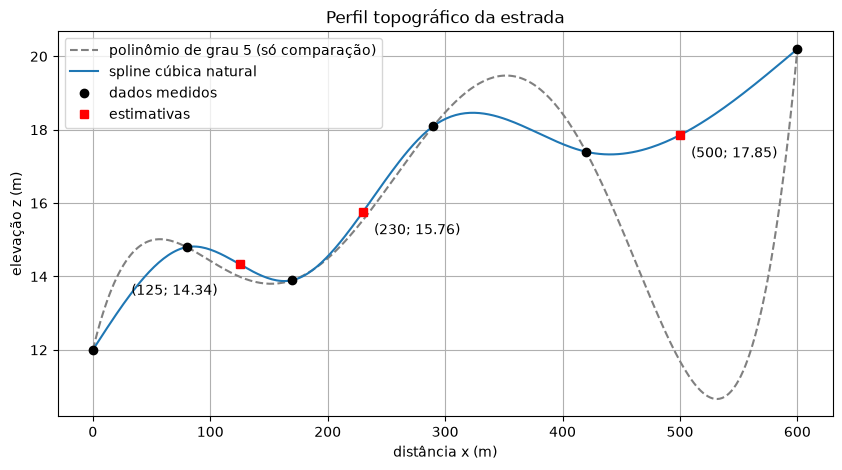

elevação mínima entre 420 e 600 m: spline = 17.33 m | polinômio de grau 5 = 10.66 m


In [47]:
xs = np.linspace(0, 600, 300)
zs = [interpol(np.array(x, dtype=float), np.array(z, dtype=float), n, d2x, xu)[0] for xu in xs] # reaproveita as d2x

# só de comparação: o polinômio de grau 5 pelos 6 pontos (lagrange)
zp = [lagrange(x, z, n, xu) for xu in xs]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(xs, zp, "--", color="gray", label="polinômio de grau 5 (só comparação)")
ax.plot(xs, zs, label="spline cúbica natural")
ax.plot(x, z, "o", color="black", label="dados medidos")
ax.plot(x_est, z_est, "s", color="red", label="estimativas")
# deslocamento de cada rótulo (o do 125 vai pra baixo e pra esquerda, pq pra direita ele bate no ponto medido de 170 m)
desloc = [(-78, -22), (8, -16), (8, -16)]
for xe, ze, d in zip(x_est, z_est, desloc):
    ax.annotate(f"({xe}; {ze:.2f})", (xe, ze), textcoords="offset points", xytext=d)
ax.set_xlabel("distância x (m)")
ax.set_ylabel("elevação z (m)")
ax.set_title("Perfil topográfico da estrada")
ax.legend()
ax.grid(True)
plt.show()

print(f"elevação mínima entre 420 e 600 m: spline = {min(z_ for x_, z_ in zip(xs, zs) if x_ >= 420):.2f} m | polinômio de grau 5 = {min(z_ for x_, z_ in zip(xs, zp) if x_ >= 420):.2f} m")

**Resposta da letra c:** o perfil sobe de 12 m pra 20,2 m ao longo dos 600 m, com um pequeno morro em 80 m, um vale em 170 m, uma subida mais forte até 290 m, uma leve descida até 420 m e a subida final até 600 m. A spline passa em todos os pontos medidos, e os 3 pontos estimados (vermelho) ficam sobre a curva, entre os nós.

A curva cinza tracejada (polinômio de grau 5 pelos mesmos 6 pontos) é só pra comparar: ela passa nos pontos, mas oscila entre os nós e **afunda pra ~10,7 m entre 420 e 600 m**, abaixo de todas as elevações medidas ali (17,4 e 20,2 m), sem respaldo nenhum nos dados. A spline fica entre ~17,3 e 20,2 m nesse trecho, pq cada intervalo é uma cúbica separada: por isso a spline é a escolha melhor pra um perfil com vários pontos.

## Exercício 4: Força de arrasto (Regressão linear e de potência)
8 medidas de `F(v)` com incerteza experimental, então a curva **n** precisa passar nos pontos (mínimos quadrados). Letras: (a) modelo linear `F = a0 + a1 v`, (b) modelo de potência `F = α v^β`, (c) 3 gráficos (dados e modelos, resíduos do linear, resíduos da potência). Em ambos: `Sr`, `RMSE = raiz(Sr/n)` e `R²`.

### Dados

In [48]:
v = [10, 20, 30, 40, 50, 60, 70, 80]                # m/s
F = [26, 94, 205, 360, 565, 790, 1090, 1420]        # N
v = np.array(v, dtype=float)
F = np.array(F, dtype=float)
n = len(v)

### a) modelo linear, F = a0 + a1 v

In [49]:
a1, a0, syx, r2, info = regress(v, F)
F_lin = a0 + a1 * v
res_lin = F - F_lin
sr_lin, rmse_lin, r2_lin = metricas(F, F_lin)

print("a) modelo linear")
print(f"F(v) = {a0:.4f} + {a1:.4f} v | info = {info}")
print(f"Sr = {sr_lin:.4f} | RMSE = {rmse_lin:.4f} N | R² = {r2_lin:.6f}")
print(f"(a regress devolve syx = {syx:.4f} = raiz(Sr/(n-2)) e R² = {r2:.6f}, que bate com o meu)")
print("F(0) previsto =", a0, "N")
print("resíduos (N) =", np.round(res_lin, 2))
print("soma dos resíduos =", np.sum(res_lin))

# confere com a lib
print("\n(a1, a0) (np.polyfit) =", np.polyfit(v, F, 1))

a) modelo linear
F(v) = -325.7857 + 19.8786 v | info = 0
Sr = 81487.5714 | RMSE = 100.9254 N | R² = 0.953199
(a regress devolve syx = 116.5387 = raiz(Sr/(n-2)) e R² = 0.953199, que bate com o meu)
F(0) previsto = -325.78571428571433 N
resíduos (N) = [ 153.     22.21  -65.57 -109.36 -103.14  -76.93   24.29  155.5 ]
soma dos resíduos = -2.842170943040401e-14

(a1, a0) (np.polyfit) = [  19.87857143 -325.78571429]


**Resposta da letra a:** `a0 ≈ -325,786 N` e `a1 ≈ 19,8786 N·s/m`, ou seja `F(v) ≈ -325,79 + 19,879 v`. `Sr ≈ 81487,6 N²`, `RMSE ≈ 100,93 N` e `R² ≈ 0,9532`. (O `syx` da `regress` é `raiz(Sr/(n-2)) ≈ 116,54 N`: usa n-2 pq perdeu 2 graus de liberdade, e o RMSE usa n.)

Só pelo `R² = 0,95` o ajuste parece bom, mas **n é**: o intercepto dá `F(0) = -325,8 N`, uma força de arrasto negativa com o ar parado, o que n tem sentido físico. Os resíduos (gráfico da letra c) mostram o motivo.

### b) modelo de potência, F = α v^β

In [50]:
# Caso C dos slides da aula 15 (methods/3_nonlinear_regression.py), função de potência y = b x^a, aqui F = α v^β (b = α, a = β)
# achata (transforma) a função de potência numa reta com ln (log natural): ln F = ln α + β ln v, reta em (ln v, ln F)
lv = np.log(v)
lF = np.log(F)
a1_ln, a0_ln, syx_log, r2_log, info = regress(lv, lF) # aplica a MMQ pra achar a reta na função achatada

# desfaz o achatamento: o a1 da reta é o β e o a0 é o ln α (por isso o exp)
beta = a1_ln
alpha = np.exp(a0_ln)

# Sr, RMSE e R² na escala original de F (a regress calcula tudo em ln, n dá pra comparar com o modelo linear)
F_pot = alpha * v ** beta
res_pot = F - F_pot
sr_pot, rmse_pot, r2_pot = metricas(F, F_pot)

print("b) modelo de potência")
print(f"F(v) = {alpha:.6f} v^{beta:.6f} | info = {info}")
print(f"Sr = {sr_pot:.4f} | RMSE = {rmse_pot:.4f} N | R² = {r2_pot:.6f}")
print(f"(R² da reta em ln: {r2_log:.6f}, outra escala, n é o R² que vale pro modelo)")
print("resíduos (N) =", np.round(res_pot, 2))
print("erro relativo (%) =", np.round(100 * res_pot / F, 2))

# confere com a lib
print("\n(β, ln α) (np.polyfit em ln) =", np.polyfit(lv, lF, 1))

# comparação dos dois modelos, na mesma régua
print("\nmodelo   |       Sr |   RMSE |       R²")
print(f"linear   | {sr_lin:>8.2f} | {rmse_lin:>6.2f} | {r2_lin:.6f}")
print(f"potência | {sr_pot:>8.2f} | {rmse_pot:>6.2f} | {r2_pot:.6f}")
print(f"Sr linear / Sr potência = {sr_lin / sr_pot:.1f}")

b) modelo de potência
F(v) = 0.298045 v^1.927829 | info = 0
Sr = 1252.0596 | RMSE = 12.5103 N | R² = 0.999281
(R² da reta em ln: 0.999775, outra escala, n é o R² que vale pro modelo)
resíduos (N) = [ 0.76 -2.04 -4.86 -5.41  3.17 -8.46 15.23 29.68]
erro relativo (%) = [ 2.92 -2.17 -2.37 -1.5   0.56 -1.07  1.4   2.09]

(β, ln α) (np.polyfit em ln) = [ 1.92782912 -1.21050974]

modelo   |       Sr |   RMSE |       R²
linear   | 81487.57 | 100.93 | 0.953199
potência |  1252.06 |  12.51 | 0.999281
Sr linear / Sr potência = 65.1


**Resposta da letra b:** `β ≈ 1,9278` e `α ≈ 0,29805`, ou seja `F(v) ≈ 0,298 v^1,928`. `Sr ≈ 1252,06 N²`, `RMSE ≈ 12,51 N` e `R² ≈ 0,99928`.

- Comparando na mesma escala (a de F): o `Sr` cai ~65 vezes em relação ao linear (81488 -> 1252) e o `R²` sobe de 0,953 pra 0,999.
- O `β ≈ 1,93` é praticamente 2: o arrasto aerodinâmico cresce com o quadrado da velocidade (`F = ½ ρ Cd A v²`), então o modelo de potência acerta a física e o linear n.
- O `R²` da reta em ln (0,99977) é de outra escala, por isso recalculei tudo em F.
- A linearização é o caso C (potência) dos slides da aula 15, o mesmo de `methods/3_nonlinear_regression.py`: `ln` em `v` e em `F`, `regress` na reta achatada, `β = a1` e `α = exp(a0)`.

### c) gráficos

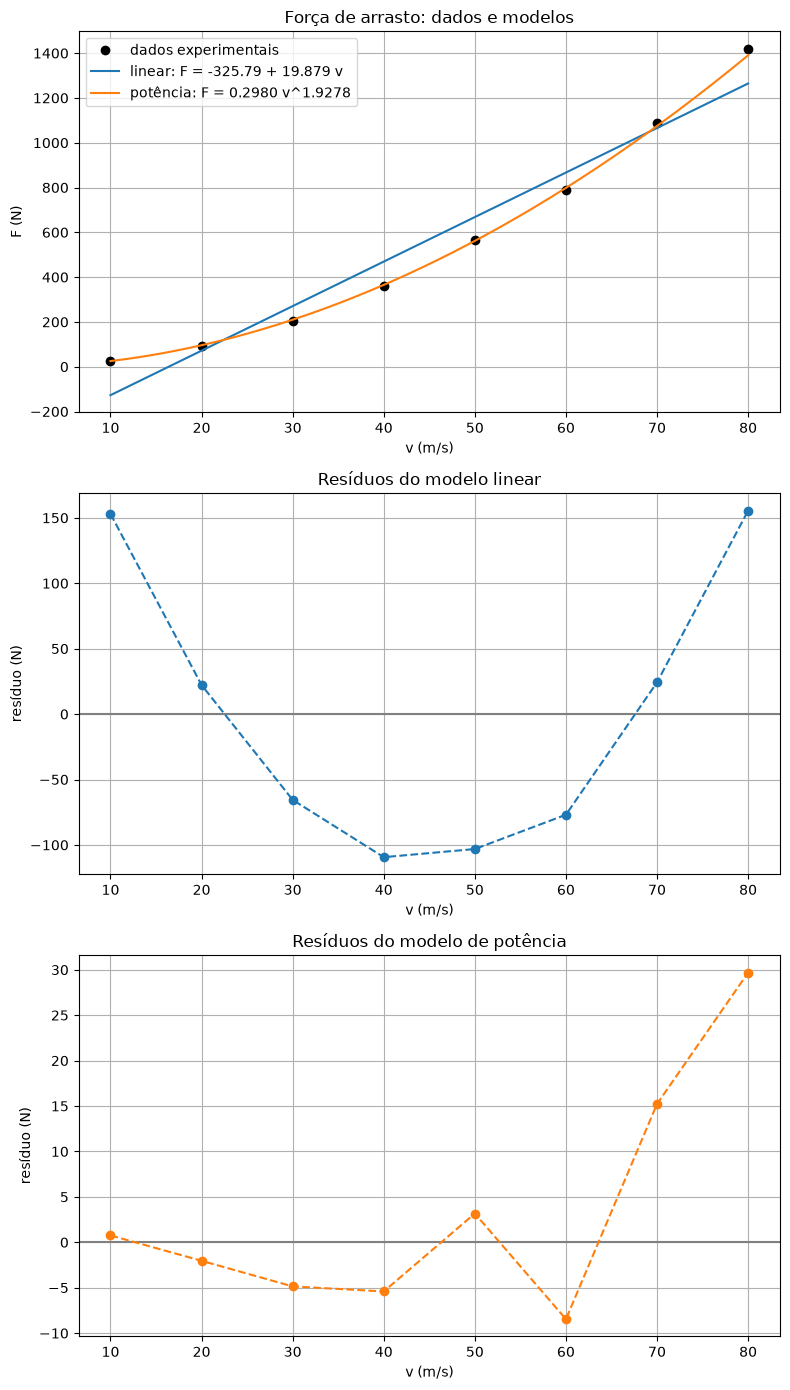

In [51]:
vs = np.linspace(10, 80, 200)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 14))

# gráfico 1: dados experimentais e os dois modelos
ax1.plot(v, F, "o", color="black", label="dados experimentais")
ax1.plot(vs, a0 + a1 * vs, label=f"linear: F = {a0:.2f} + {a1:.3f} v")
ax1.plot(vs, alpha * vs ** beta, label=f"potência: F = {alpha:.4f} v^{beta:.4f}")
ax1.set_xlabel("v (m/s)")
ax1.set_ylabel("F (N)")
ax1.set_title("Força de arrasto: dados e modelos")
ax1.legend()
ax1.grid(True)

# gráfico 2: resíduos do modelo linear (F_i - modelo(v_i))
ax2.axhline(0, color="gray")
ax2.plot(v, res_lin, "o--", color="tab:blue")
ax2.set_xlabel("v (m/s)")
ax2.set_ylabel("resíduo (N)")
ax2.set_title("Resíduos do modelo linear")
ax2.grid(True)

# gráfico 3: resíduos do modelo de potência
ax3.axhline(0, color="gray")
ax3.plot(v, res_pot, "o--", color="tab:orange")
ax3.set_xlabel("v (m/s)")
ax3.set_ylabel("resíduo (N)")
ax3.set_title("Resíduos do modelo de potência")
ax3.grid(True)

plt.tight_layout()
plt.show()

**Resposta da letra c:**

- **Gráfico 1:** a reta n acompanha a curvatura dos dados: fica abaixo dos pontos nas pontas (v = 10 e v = 80) e acima deles no meio. A curva de potência passa praticamente em cima de todos os pontos.
- **Gráfico 2 (linear):** os resíduos têm formato de **U**: +153 N em v = 10, negativos no meio (até -109 N em v = 40) e +155,5 N em v = 80. Isso é erro **sistemático**, n aleatório: o modelo tem a forma errada (os dados são curvos). Um bom ajuste teria resíduos espalhados em volta de zero, sem padrão.
- **Gráfico 3 (potência):** os resíduos são bem menores (entre -8,5 e +29,7 N) e sem o formato de U. Eles crescem em módulo com a velocidade, mas em erro relativo ficam entre ~0,6 % e ~2,9 % pra todos os pontos, pq o ajuste em ln minimiza erros relativos. Os 2 últimos resíduos são positivos e maiores (+15,2 e +29,7 N): o modelo subestima um pouco nas velocidades mais altas.

**Conclusão:** o modelo de potência é o mais adequado pra esses dados (menor `Sr` e `RMSE`, `R²` maior, resíduos sem padrão e `β ≈ 2` coerente com a física). Mesmo assim o `R²` do linear (0,95) parecia alto: só o gráfico de resíduos mostra que o modelo tá errado, então n dá pra julgar um ajuste só pelo `R²`.

## Quadro comparativo dos métodos

In [52]:
# interpoladores: erro máximo nos pontos dados (tem que ser ~0, pq a curva passa neles). Ajustes: R² (a curva n passa nos pontos, só chega perto)
linhas = [
    ["Lagrange",              "Ex 1 (5 pts, grau 4)",  "interpola", f"R(35) = {R_est[0]:.4f}", f"{err_ex1:.2e}"],
    ["Newton (dif. divididas)", "Ex 2 (5 pts, grau 4)", "interpola", f"η(32) = {eta_est[0]:.4f}", f"{err_ex2:.2e}"],
    ["Spline cúbica natural", "Ex 3 (6 pts, 5 cúbicas)", "interpola", f"z(125) = {z_est[0]:.4f}", f"{err_ex3:.2e}"],
    ["Regressão linear",      "Ex 4 (8 pts)",          "ajusta",    f"Sr = {sr_lin:.1f}", f"R² = {r2_lin:.4f}"],
    ["Regressão potência",    "Ex 4 (8 pts)",          "ajusta",    f"Sr = {sr_pot:.1f}", f"R² = {r2_pot:.4f}"],
]
print(f"{'método':<26}{'problema':<26}{'tipo':<11}{'resultado':<20}{'erro nos pontos / R²'}")
print("-" * 95)
for nome, prob, tipo, res, e in linhas:
    print(f"{nome:<26}{prob:<26}{tipo:<11}{res:<20}{e}")

método                    problema                  tipo       resultado           erro nos pontos / R²
-----------------------------------------------------------------------------------------------
Lagrange                  Ex 1 (5 pts, grau 4)      interpola  R(35) = 113.6071    1.42e-14
Newton (dif. divididas)   Ex 2 (5 pts, grau 4)      interpola  η(32) = 78.6052     1.42e-14
Spline cúbica natural     Ex 3 (6 pts, 5 cúbicas)   interpola  z(125) = 14.3350    1.78e-15
Regressão linear          Ex 4 (8 pts)              ajusta     Sr = 81487.6        R² = 0.9532
Regressão potência        Ex 4 (8 pts)              ajusta     Sr = 1252.1         R² = 0.9993


Os 3 interpoladores passam em todos os pontos (erro ~1e-14, só arredondamento), e são os certos quando os dados são exatos ou quase (calibração, tabela de ensaio, medição topográfica). Já com dados com dispersão (Ex 4), passar em todos os pontos n é o objetivo: a regressão acha a tendência, e o gráfico de resíduos diz se o modelo escolhido serve.